# Laboratorium 6 — Warstwa łącząca i pełna CNN

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
epochs = 6

In [2]:
x = torch.tensor([[1., 2., 5., 6.],
                  [3., 4., 7., 8.],
                  [9., 1., 2., 0.],
                  [8., 6., 4., 3.]]).reshape(1, 1, 4, 4)
print("Max pooling:", nn.MaxPool2d(2)(x)[0, 0])
print("Average pooling:", nn.AvgPool2d(2)(x)[0, 0])
features = torch.zeros(1, 64, 7, 7)
print("GAP:", tuple(features.shape), "→",
      tuple(nn.AdaptiveAvgPool2d(1)(features).shape))

Max pooling: tensor([[4., 8.],
        [9., 4.]])
Average pooling: tensor([[2.5000, 6.5000],
        [6.0000, 2.2500]])
GAP: (1, 64, 7, 7) → (1, 64, 1, 1)


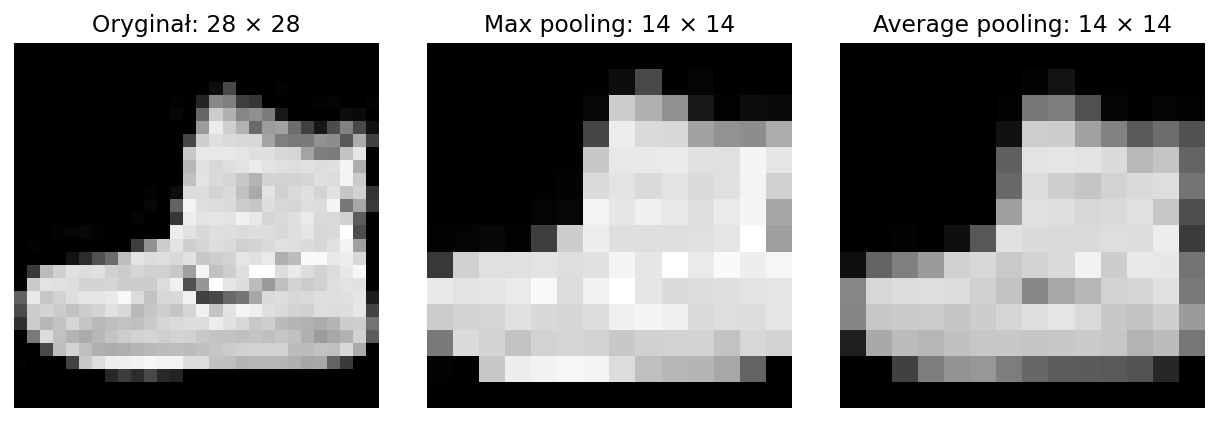

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])
train_data = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)
test_loader = DataLoader(test_data, batch_size=256)

image = train_data.data[0].float().reshape(1, 1, 28, 28) / 255
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, name, value in zip(
    axes,
    ["Oryginał", "Max pooling", "Average pooling"],
    [image, nn.MaxPool2d(2)(image), nn.AvgPool2d(2)(image)]
):
    ax.imshow(value[0, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}: {value.shape[-2]} × {value.shape[-1]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
class CNN(nn.Module):
    def __init__(self, variant):
        super().__init__()
        layers = []
        for cin, cout in [(1, 32), (32, 64)]:
            layers += [nn.Conv2d(cin, cout, 3, padding=1),
                       nn.BatchNorm2d(cout), nn.ReLU()]
            if variant == "max":
                layers.append(nn.MaxPool2d(2))
            elif variant == "avg":
                layers.append(nn.AvgPool2d(2))
            else:
                layers += [nn.Conv2d(cout, cout, 3, stride=2, padding=1),
                           nn.BatchNorm2d(cout), nn.ReLU()]
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Linear(64, 10))

    def forward(self, x):
        return self.head(self.features(x))

In [5]:
results = {}
for variant in ["max", "avg", "stride"]:
    torch.manual_seed(0)
    train_loader = DataLoader(
        train_data, batch_size=128, shuffle=True,
        generator=torch.Generator().manual_seed(0)
    )
    model = CNN(variant).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    train_accuracy, test_accuracy = [], []
    for epoch in range(epochs):
        model.train()
        correct = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(images)
            criterion(logits, labels).backward()
            optimizer.step()
            correct += (logits.argmax(1) == labels).sum().item()
        train_accuracy.append(correct / len(train_data))
        model.eval()
        correct = 0
        with torch.inference_mode():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                correct += (model(images).argmax(1) == labels).sum().item()
        test_accuracy.append(correct / len(test_data))
        print(f"{variant}, epoka {epoch + 1}: accuracy test = {test_accuracy[-1]:.2%}")
    with torch.inference_mode():
        shape = tuple(model.features(torch.zeros(1, 1, 28, 28, device=device)).shape[1:])
    results[variant] = {
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "parameters": sum(p.numel() for p in model.parameters()),
        "feature_shape": shape
    }

max, epoka 1: accuracy test = 72.11%
max, epoka 2: accuracy test = 78.18%
max, epoka 3: accuracy test = 81.26%
max, epoka 4: accuracy test = 82.35%
max, epoka 5: accuracy test = 79.45%
max, epoka 6: accuracy test = 81.40%
avg, epoka 1: accuracy test = 67.46%
avg, epoka 2: accuracy test = 75.33%
avg, epoka 3: accuracy test = 77.57%
avg, epoka 4: accuracy test = 80.42%
avg, epoka 5: accuracy test = 79.96%
avg, epoka 6: accuracy test = 79.98%
stride, epoka 1: accuracy test = 82.31%
stride, epoka 2: accuracy test = 87.62%
stride, epoka 3: accuracy test = 87.38%
stride, epoka 4: accuracy test = 88.42%
stride, epoka 5: accuracy test = 88.50%
stride, epoka 6: accuracy test = 89.23%


Wariant      Accuracy (6)   Najlepsza acc.    Parametry        Mapa cech
max               81.40%          82.35%        19658       (64, 7, 7)
avg               79.98%          80.42%        19658       (64, 7, 7)
stride            89.23%          89.23%        66026       (64, 7, 7)


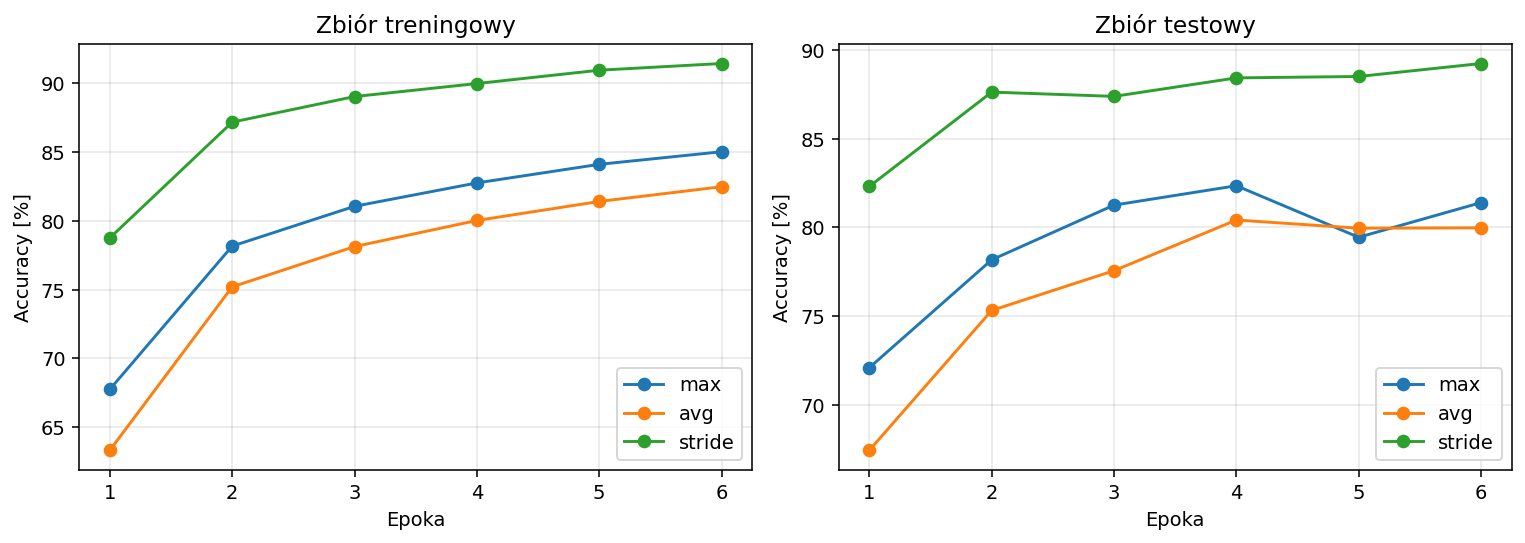

In [6]:
print(f"{'Wariant':<10} {'Accuracy (6)':>14} {'Najlepsza acc.':>16} {'Parametry':>12} {'Mapa cech':>16}")
for variant, result in results.items():
    accuracy = result["test_accuracy"]
    print(f"{variant:<10} {accuracy[-1]:>13.2%} {max(accuracy):>15.2%} "
          f"{result['parameters']:>12} {str(result['feature_shape']):>16}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for variant, result in results.items():
    for ax, key in zip(axes, ["train_accuracy", "test_accuracy"]):
        ax.plot(range(1, epochs + 1), [100 * a for a in result[key]],
                marker="o", label=variant)
for ax, title in zip(axes, ["Zbiór treningowy", "Zbiór testowy"]):
    ax.set(title=title, xlabel="Epoka", ylabel="Accuracy [%]", xticks=range(1, epochs + 1))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("krzywe_accuracy_lab_06.png", dpi=160)
plt.show()